In [1]:
# Permite que la imagen se dibuje en el jupyter
%matplotlib inline

# Que la imagen termine con una mejor resolución
%config InlineBackend.figure_format = 'retina'

import numpy as np
import torch
from torch import nn
from torch import optim
import torch.nn.functional as F
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import kagglehub
import os
import shutil


print("Librerías importadas correctamente")

Librerías importadas correctamente


In [2]:
# Ahora realizamos la configuracion del dispositivo

# Definir el dispositivo
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Usando dispositivo: {device}\n")

Usando dispositivo: cpu



In [3]:
# Ahora mostraremos donde esta el dataset
dataset_path = 'data/grape-disease-dataset'
print(f"Dataset en: {dataset_path}\n")

Dataset en: data/grape-disease-dataset



In [4]:
# Vamos a definir las transformaciones y cargar el dataset

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

print("Transformación definida")

# Uso la ruta local
trainset = datasets.ImageFolder(dataset_path + '/Original Data/train/', transform=transform)
testset = datasets.ImageFolder(dataset_path + '/Original Data/test/', transform=transform)

# Crear DataLoader
trainloader = torch.utils.data.DataLoader(trainset, batch_size=64, shuffle=True)
testloader = torch.utils.data.DataLoader(testset, batch_size=64, shuffle=False)

num_classes = len(trainset.classes)
print(f"Número de clases: {num_classes}")
print(f"Clases: {trainset.classes}")
print(f"Imágenes de entrenamiento: {len(trainset)}")
print(f"Imágenes de prueba: {len(testset)}\n")

Transformación definida
Número de clases: 4
Clases: ['Black Rot', 'ESCA', 'Healthy', 'Leaf Blight']
Imágenes de entrenamiento: 7222
Imágenes de prueba: 1805



In [5]:
# Pasamos a la creacion de la red neuronal

class RedUvas(nn.Module):
    def __init__(self, num_classes):
        super(RedUvas, self).__init__()
        self.fc1 = nn.Linear(150528, 256)  # 224*224*3
        self.fc2 = nn.Linear(256, 128)
        self.fc3 = nn.Linear(128, num_classes)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.3) # Nos ayuda a evitar el overfitting que memoriza los datos en lugar de aprender patrones, apaga aleatoriamente algunas neuronas

    # Define como fluyen los datos a traves de la red neurinal    
    def forward(self, x):
        x = x.view(x.size(0), -1)  # Aplanar
        x = self.relu(self.fc1(x)) # Capa 1 + actiuvacion ReLu
        x = self.dropout(x) # Apagar algunas neuronas .........
        x = self.relu(self.fc2(x))
        x = self.dropout(x)
        x = self.fc3(x)
        return x

model = RedUvas(num_classes)
model = model.to(device)
print("Modelo creado exitosamente\n")

Modelo creado exitosamente



In [6]:
# Ahora lo que hacemos es definir loss y optimizador para entrenar

criterion = nn.CrossEntropyLoss() # Mide que tabn mal predice el modelo
optimizer = optim.Adam(model.parameters(), lr=0.001) # Actualiza los pesos del modelo para reducir la perdida (Calcula gradientes, mueve los pesos, reduce perdida poco a poco)
print("Loss function y optimizador definidos\n")

Loss function y optimizador definidos



In [7]:
# Ahora pasamos a realizar la funcion de entrenamiento

# Hiperparámetros
epochs = 3
print_every = 40
steps = 0

print("Entrenamiento iniciado")

for e in range(epochs):
    running_loss = 0
    
    for images, labels in trainloader:
        steps += 1
        
        # Empieza con el pase hacia adelante
        output = model(images) # Las imagenes entran al modelo
        loss = criterion(output, labels) # Calcula el costo y el error
        
        # Ahora con el pase hacia atras para que aprenda de sus errores y ajuste los pesos
        optimizer.zero_grad() # Limpia los gradientes anteriores
        loss.backward() # Calcula los gradientes hacia atras
        optimizer.step() # Permite actualizar los pesos
        
        running_loss += loss.item()
        
        # Imprimir cada X pasos
        if steps % print_every == 0:
            print(f"Época {e+1}/{epochs} ... Pérdida: {running_loss/print_every:.4f}")
            running_loss = 0

print("Entrenamiento completado")

Entrenamiento iniciado
Época 1/3 ... Pérdida: 2.5514
Época 1/3 ... Pérdida: 0.7897
Época 2/3 ... Pérdida: 0.1142
Época 2/3 ... Pérdida: 0.5749
Época 2/3 ... Pérdida: 0.5837
Época 3/3 ... Pérdida: 0.1564
Época 3/3 ... Pérdida: 0.4945
Época 3/3 ... Pérdida: 0.4522
Entrenamiento completado


In [8]:
# Calcular precisión GRAPE DISEASE


correct = 0
total = 0

with torch.no_grad():
    for images, labels in trainloader:
        images = images.to(device)
        labels = labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print(f"Precisión Grape Disease: {accuracy:.2f}%")

Precisión Grape Disease: 82.35%


Tamaño del lote: torch.Size([64, 3, 224, 224])
Etiquetas: tensor([3, 1, 1, 1, 1, 0, 3, 0, 0, 2])

Salida de la red (probabilidades):
tensor([[2.3688e-05, 2.4710e-08, 9.7559e-16, 9.9998e-01]])

Predicción: 3
Verdadero: 3
Clase predicha: Leaf Blight
Clase verdadera: Leaf Blight
Confianza: 100.00%

Probabilidades por clase:
  Black Rot: 0.00%
  ESCA: 0.00%
  Healthy: 0.00%
  Leaf Blight: 100.00%


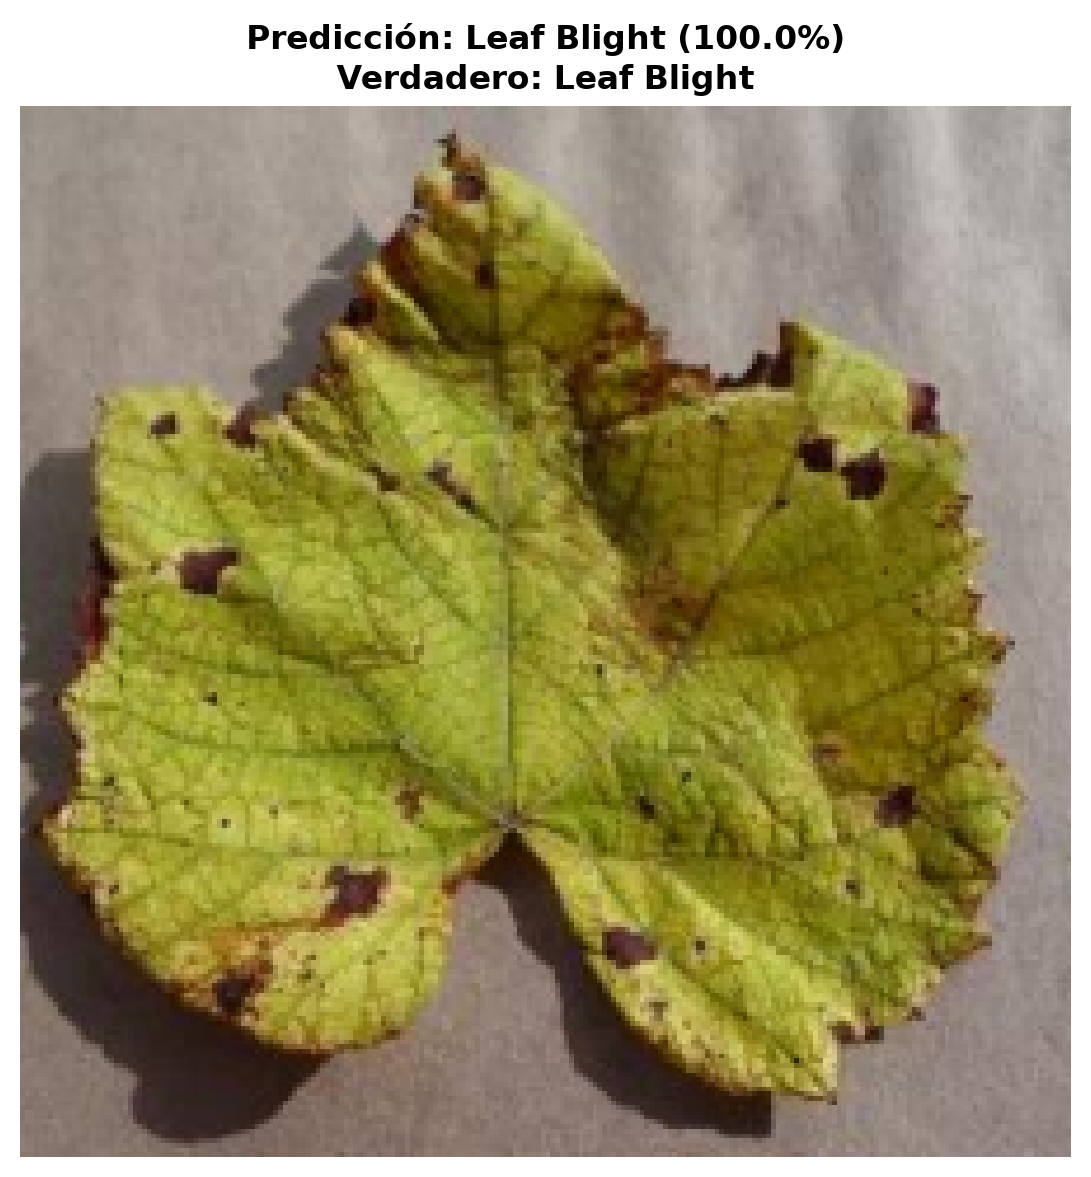

In [9]:
# Ahora nos daremos cuenta si nuestro modelo realmente aprendio

# Definir el dispositivo
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Obtener un lote de imágenes del dataset
dataiter = iter(trainloader)
images, labels = next(dataiter)

print(f"Tamaño del lote: {images.shape}")
print(f"Etiquetas: {labels[:10]}")
print()

# Mover imágenes al dispositivo
images_device = images.to(device)

# Hacer predicción con la primera imagen
with torch.no_grad():
    output = model(images_device[0].unsqueeze(0))
    ps = torch.nn.functional.softmax(output, dim=1)

# Obtener la predicción
pred = torch.argmax(ps, dim=1)
pred_prob = ps[0][pred].item() * 100


print("Salida de la red (probabilidades):")
print(ps)
print()

print(f"Predicción: {pred.item()}")
print(f"Verdadero: {labels[0].item()}")
print(f"Clase predicha: {trainset.classes[pred.item()]}")
print(f"Clase verdadera: {trainset.classes[labels[0].item()]}")
print(f"Confianza: {pred_prob:.2f}%")
print()

# Mostrar todas las probabilidades
print("Probabilidades por clase:")
for i, class_name in enumerate(trainset.classes):
    prob = ps[0][i].item() * 100
    print(f"  {class_name}: {prob:.2f}%")


# Desnormalizar la imagen
img = images[0].numpy().transpose(1, 2, 0)
img = img * 0.5 + 0.5  # Deshace la normalización

# Mostrar imagen
plt.figure(figsize=(8, 6))
plt.imshow(img)
plt.title(f"Predicción: {trainset.classes[pred.item()]} ({pred_prob:.1f}%)\nVerdadero: {trainset.classes[labels[0].item()]}", 
          fontsize=12, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()